# Prediksi Keterlambatan Paket — Kasus 08

**Mata kuliah:** Machine Learning · Kelas 5B  
**Anggota:** Bob Nolen Barnabas Munthe (2406157) dan Muhammad Riyu Saputra (NIM belum terverifikasi)

## 1. Masalah dan tujuan
Saat paket dijemput di hub Bandung, petugas ingin memperkirakan risiko keterlambatan agar CS dapat memberi peringatan lebih awal. Target `terlambat` bernilai 1 untuk terlambat dan 0 untuk tidak terlambat. Kita membandingkan regresi logistik sebagai baseline wajib dengan HistGradientBoosting, menggunakan **average precision (AP), ringkasan kurva precision–recall**, sebagai ukuran utama. AP bukan akurasi dan bukan integral trapezoidal kurva PR.

Data berasal dari **dataset sintetis pengajar**, bukan catatan pengiriman nyata milik kelompok. Model ini masih bahan pembelajaran, belum layak dipakai untuk keputusan operasional.

**Sumber:** [repositori pengajar](https://github.com/nurhikam/mkb-ml-project), [brief kasus 08](https://github.com/nurhikam/mkb-ml-project/blob/main/kasus/08-keterlambatan-paket/brief.md). Nomor 8 pada sheet Bob/Riyu konsisten dengan kasus 08, tetapi gambar daftar topik dari PJ belum berhasil dicocokkan.

### Cara membaca dan menjalankan
Jalankan sel dari atas ke bawah. Semua langkah pengolahan dan pelatihan terlihat langsung di notebook; tidak ada paket proyek tersembunyi atau instalasi tambahan. Output yang disimpan pada revisi ini berasal dari **eksekusi lokal file notebook**, bukan runtime Google Colab. Menjalankan ulang di Colab akan menghitung ulang TRAIN/VALID saja; versi pustaka dapat menyebabkan sedikit perbedaan.

**Batas evaluasi:** TEST April–Juni 2026 sudah dievaluasi pada eksperimen awal. CSV mentah dibaca utuh lalu baris TEST segera disaring sebelum EDA; target TEST tidak dianalisis, TEST tidak diprediksi, dan angka TEST tidak dipakai untuk memilih model/threshold. Hasil TEST lama ditampilkan terpisah sebagai catatan historis, bukan hasil pelatihan ulang. Kontribusi implementasi/commit anggota belum dibuktikan; notebook disusun dengan bantuan AI dan perlu dipahami kedua anggota.

## 2. Impor pustaka
NumPy dan pandas dipakai untuk data, Matplotlib untuk grafik, dan scikit-learn untuk preprocessing serta model. Kita mencetak versi yang benar-benar digunakan, tanpa memaksa instalasi versi tertentu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix
from IPython.display import display

print("NumPy:", np.__version__, "| pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)


NumPy: 2.4.3 | pandas: 3.0.6
scikit-learn: 1.9.0


## 3. Membaca data dan membatasi periode
CSV dibaca langsung dari URL publik pengajar. Pemisahan waktu dilakukan **sebelum EDA**, supaya analisis di bawah hanya memakai TRAIN/VALID. Baris mulai April 2026 dibuang dari ruang kerja, bukan dijadikan data uji baru.

Jika URL tidak dapat diakses, unduh `raw.csv` dari sumber yang sama, unggah melalui panel Files Colab, lalu ganti `SUMBER_DATA` menjadi `"/content/raw.csv"`. Sidik SHA-256 memastikan isinya masih sama dengan dataset eksperimen awal.

In [2]:
SUMBER_DATA = "https://raw.githubusercontent.com/nurhikam/mkb-ml-project/main/kasus/08-keterlambatan-paket/data/raw.csv"
# Alternatif setelah upload manual: SUMBER_DATA = "/content/raw.csv"
import hashlib
from urllib.request import urlopen
from io import BytesIO
from pathlib import Path

if SUMBER_DATA.startswith("https://"):
    isi_csv = urlopen(SUMBER_DATA, timeout=60).read()
else:
    isi_csv = Path(SUMBER_DATA).read_bytes()
sha_data = hashlib.sha256(isi_csv).hexdigest()
assert sha_data == "2821b50eac1b02181cacbfb52fca784b2b5be930c73e5c671a877eeec6a600ab", "Dataset berbeda; hentikan dan tinjau sumber."
data_awal = pd.read_csv(BytesIO(isi_csv))
tanggal = pd.to_datetime(data_awal["tanggal_pickup"], errors="raise")
data = data_awal.loc[tanggal < "2026-04-01"].copy()
del data_awal, tanggal, isi_csv
print("SHA-256 sumber:", sha_data)
print("Baris TRAIN/VALID sebelum deduplikasi:", len(data))
display(data.head())


SHA-256 sumber: 2821b50eac1b02181cacbfb52fca784b2b5be930c73e5c671a877eeec6a600ab
Baris TRAIN/VALID sebelum deduplikasi: 33694


,id_resi,tanggal_pickup,jam_pickup,kota_tujuan,jarak_km,jumlah_transit,layanan,janji_hari,berat_kg,metode_bayar,cuaca_saat_pickup,volume_hub_hari,terlambat
0,BDG69958899,2025-01-01,14,Tasikmalaya,109.0,2,HEMAT,4,5.93,COD,berawan,4990,0
1,BDG98718051,2025-01-01,15,Surabaya,678.0,2,HEMAT,5,0.78,non_COD,berawan,4769,0
2,BDG40074637,2025-01-01,14,Bekasi,128.0,1,REG,2,2.57,COD,cerah,4286,0
3,BDG00168612,2025-01-01,14,Pontianak,885.0,3,REG,3,1.12,COD,cerah,4856,1
4,BDG72495951,2025-01-01,12,Denpasar,1057.0,3,EXPRESS,3,1.68,non_COD,berawan,5467,0


## 4. Pemeriksaan data dan pembagian kronologis
Duplikat identik dihapus sebelum pembagian. TRAIN mencakup tahun 2025, sedangkan VALID Januari–Maret 2026. Resi tidak boleh muncul pada dua bagian. Ringkasan di sel ini tidak memuat periode TEST.

Inventaris awal proyek pernah melihat statistik target mentah keseluruhan. Jadi, pemisahan historis tidak diklaim sebagai holdout yang sejak awal sepenuhnya tertutup.

In [3]:
jumlah_duplikat = int(data.duplicated().sum())
data = data.drop_duplicates().copy()
data["tanggal_pickup"] = pd.to_datetime(data["tanggal_pickup"], errors="raise")
data = data.set_index("id_resi", verify_integrity=True)
train = data.loc[data["tanggal_pickup"] < "2026-01-01"].copy()
valid = data.loc[data["tanggal_pickup"] >= "2026-01-01"].copy()
assert train.index.intersection(valid.index).empty
assert train["tanggal_pickup"].max() < valid["tanggal_pickup"].min()
assert set(data["terlambat"].unique()) <= {0, 1}
print("Duplikat TRAIN/VALID dihapus:", jumlah_duplikat)
display(pd.DataFrame([
    {"bagian": nama, "baris": len(bagian), "awal": bagian.tanggal_pickup.min(), "akhir": bagian.tanggal_pickup.max()}
    for nama, bagian in [("TRAIN", train), ("VALID", valid)]
]))
train.info()
display(train.isna().sum().rename("kosong_TRAIN").to_frame())


Duplikat TRAIN/VALID dihapus: 438


C:\Users\HELIOS NEO\AppData\Local\Temp\ipykernel_34952\4136882900.py:4: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  data = data.set_index("id_resi", verify_integrity=True)


,bagian,baris,awal,akhir
0,TRAIN,26633,2025-01-01,2025-12-31
1,VALID,6623,2026-01-01,2026-03-31


<class 'pandas.DataFrame'>
Index: 26633 entries, BDG69958899 to BDG72596139
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   tanggal_pickup     26633 non-null  datetime64[us]
 1   jam_pickup         26633 non-null  int64         
 2   kota_tujuan        26633 non-null  str           
 3   jarak_km           26133 non-null  float64       
 4   jumlah_transit     26633 non-null  int64         
 5   layanan            26633 non-null  str           
 6   janji_hari         26633 non-null  int64         
 7   berat_kg           26633 non-null  float64       
 8   metode_bayar       26633 non-null  str           
 9   cuaca_saat_pickup  26381 non-null  str           
 10  volume_hub_hari    26633 non-null  int64         
 11  terlambat          26633 non-null  int64         
dtypes: datetime64[us](1), float64(2), int64(5), str(4)
memory usage: 3.6+ MB


,kosong_TRAIN
tanggal_pickup,0
jam_pickup,0
kota_tujuan,0
jarak_km,500
jumlah_transit,0
layanan,0
janji_hari,0
berat_kg,0
metode_bayar,0
cuaca_saat_pickup,252


## 5. Pemilihan fitur dan cleaning
Fitur asli tetap dipakai tanpa membuat fitur baru. `id_resi` adalah identitas, `tanggal_pickup` hanya untuk split, dan `volume_hub_hari` dikeluarkan karena total satu hari belum diketahui saat pickup.

Ejaan kota dan layanan diseragamkan. Nilai numerik tidak valid dijadikan kosong; median/modus **baru dipelajari dari TRAIN** pada preprocessing. Batas berat 100 kg adalah asumsi lingkup demo, bukan bukti salah satuan atau aturan dari pengajar; tidak ada konversi gram.

**Asumsi penting:** `jumlah_transit` sementara diperlakukan sebagai rencana yang tersedia saat pickup. Brief belum memastikan apakah nilainya rencana atau realisasi. Jika ternyata realisasi, ada risiko kebocoran informasi. Perbaikan substantif membutuhkan eksperimen prospektif dan holdout baru, bukan mencoba-coba pada TEST lama.

In [4]:
numerik = ["jam_pickup", "jarak_km", "jumlah_transit", "janji_hari", "berat_kg"]
kategori = ["kota_tujuan", "layanan", "metode_bayar", "cuaca_saat_pickup"]
fitur = numerik + kategori
peta_kota = {
    "sby": "Surabaya", "surabaya": "Surabaya", "dki jakarta": "Jakarta",
    "jakarta": "Jakarta", "jkt": "Jakarta", "kota bekasi": "Bekasi", "bekasi": "Bekasi",
    "di yogyakarta": "Yogyakarta", "yogya": "Yogyakarta", "jogja": "Yogyakarta",
    "yogyakarta": "Yogyakarta", "bali": "Denpasar", "denpasar": "Denpasar", "medan": "Medan"
}

def bersihkan(frame):
    hasil = frame.reindex(columns=fitur).copy()
    for kolom in numerik:
        hasil[kolom] = pd.to_numeric(hasil[kolom], errors="coerce").replace([np.inf, -np.inf], np.nan)
    for kolom in kategori:
        hasil[kolom] = hasil[kolom].map(lambda x: str(x).strip() if pd.notna(x) else np.nan)
    hasil["kota_tujuan"] = hasil["kota_tujuan"].map(
        lambda x: peta_kota.get(x.lower(), x.title()) if isinstance(x, str) else np.nan)
    hasil["layanan"] = hasil["layanan"].map(
        lambda x: {"EXP": "EXPRESS", "EXPRESS": "EXPRESS", "REG": "REG", "HEMAT": "HEMAT"}.get(x.upper(), np.nan)
        if isinstance(x, str) else np.nan)
    hasil.loc[(hasil.berat_kg <= 0) | (hasil.berat_kg > 100), "berat_kg"] = np.nan
    hasil.loc[hasil.jarak_km <= 0, "jarak_km"] = np.nan
    return hasil

X_train = bersihkan(train)
X_valid = bersihkan(valid)
y_train = train["terlambat"].astype(int)
y_valid = valid["terlambat"].astype(int)
display(pd.DataFrame({"kosong_sebelum_TRAIN": train[fitur].isna().sum(),
                      "kosong_setelah_TRAIN": X_train.isna().sum()}))
display(X_train.head())


,kosong_sebelum_TRAIN,kosong_setelah_TRAIN
jam_pickup,0,0
jarak_km,500,500
jumlah_transit,0,0
janji_hari,0,0
berat_kg,0,877
kota_tujuan,0,0
layanan,0,0
metode_bayar,0,0
cuaca_saat_pickup,252,252


,jam_pickup,jarak_km,jumlah_transit,janji_hari,berat_kg,kota_tujuan,layanan,metode_bayar,cuaca_saat_pickup
id_resi,,,,,,,,,
BDG69958899,14,109.0,2,4,5.93,Tasikmalaya,HEMAT,COD,berawan
BDG98718051,15,678.0,2,5,0.78,Surabaya,HEMAT,non_COD,berawan
BDG40074637,14,128.0,1,2,2.57,Bekasi,REG,COD,cerah
BDG00168612,14,885.0,3,3,1.12,Pontianak,REG,COD,cerah
BDG72495951,12,1057.0,3,3,1.68,Denpasar,EXPRESS,non_COD,berawan


## 6. EDA pada TRAIN
Grafik berikut memperlihatkan keseimbangan kelas serta distribusi jarak dan layanan. Sebaran kelas perlu diperhatikan: akurasi saja dapat menutupi kegagalan menemukan paket terlambat. Tidak ada statistik TEST yang dihitung di sini.

,jam_pickup,jarak_km,jumlah_transit,janji_hari,berat_kg
count,26633.00,26133.0,26633.00,26633.00,25756.00
mean,13.55,535.6,2.09,2.90,2.04
std,3.40,519.1,1.14,1.24,2.41
min,7.00,92.0,1.00,1.00,0.10
25%,11.00,135.0,1.00,2.00,0.73
50%,14.00,356.0,2.00,3.00,1.34
75%,16.00,787.0,3.00,4.00,2.47
max,22.00,2194.0,5.00,6.00,100.00


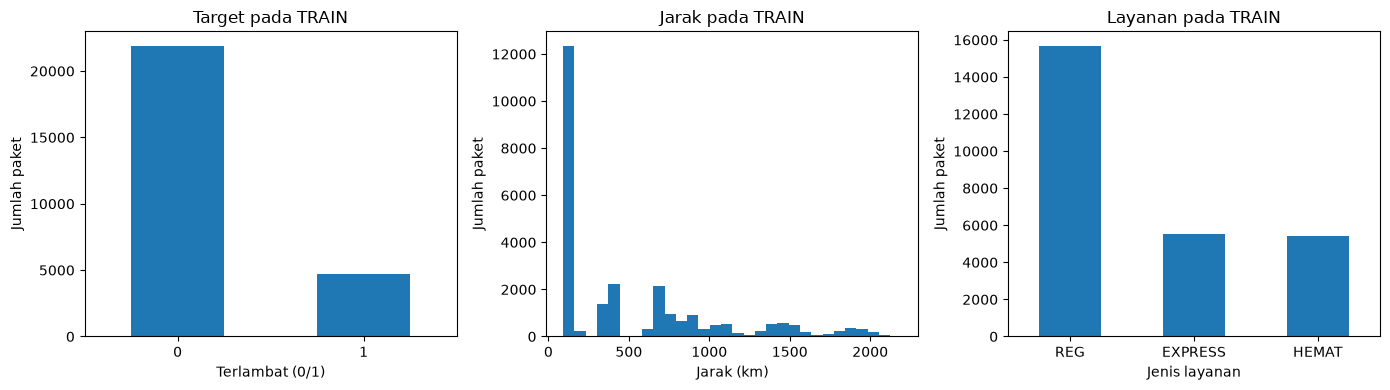

Proporsi terlambat TRAIN: 0.1778


In [5]:
display(X_train[numerik].describe().round(2))
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
y_train.value_counts().sort_index().plot.bar(ax=ax[0], rot=0)
ax[0].set(title="Target pada TRAIN", xlabel="Terlambat (0/1)", ylabel="Jumlah paket")
X_train["jarak_km"].plot.hist(bins=30, ax=ax[1])
ax[1].set(title="Jarak pada TRAIN", xlabel="Jarak (km)", ylabel="Jumlah paket")
X_train["layanan"].value_counts().plot.bar(ax=ax[2], rot=0)
ax[2].set(title="Layanan pada TRAIN", xlabel="Jenis layanan", ylabel="Jumlah paket")
plt.tight_layout()
plt.show()
print("Proporsi terlambat TRAIN:", round(y_train.mean(), 4))


## 7. Preprocessing dan baseline regresi logistik
Pipeline numerik mengisi nilai kosong dengan median TRAIN, menambahkan indikator kosong, lalu melakukan standardisasi. Pipeline kategori mengisi dengan modus TRAIN dan melakukan one-hot encoding. Kategori baru pada VALID/demo diabaikan oleh encoder, bukan digunakan untuk belajar ulang.

Regresi logistik menjadi baseline dengan fitur asli. `.fit()` hanya menerima TRAIN; VALID hanya untuk menghitung prediksi. Fungsi kecil di bawah hanya membangun preprocessing yang terlihat lengkap, bukan menjalankan seluruh proyek secara tersembunyi.

In [6]:
def buat_preprocessing():
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler())
        ]), numerik),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), kategori)
    ])

baseline = Pipeline([
    ("preprocess", buat_preprocessing()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
baseline.fit(X_train, y_train)
p_valid_baseline = baseline.predict_proba(X_valid)[:, 1]
ap_baseline = average_precision_score(y_valid, p_valid_baseline)
print("Baseline AP VALID:", ap_baseline)


Baseline AP VALID: 0.4093617076003751


## 8. Model pembanding dan kurva precision–recall
HistGradientBoosting dapat menangkap hubungan nonlinier. Konfigurasi berikut mengikuti perbandingan dua model pada eksperimen awal; tidak dilakukan pencarian parameter baru. Model dipilih berdasarkan AP VALID tertinggi, tanpa refit TRAIN+VALID dan tanpa menyentuh TEST.

,model,AP_VALID
1,hist_gradient_boosting,0.422425
0,logistic_regression,0.409362


Terpilih berdasarkan VALID: hist_gradient_boosting


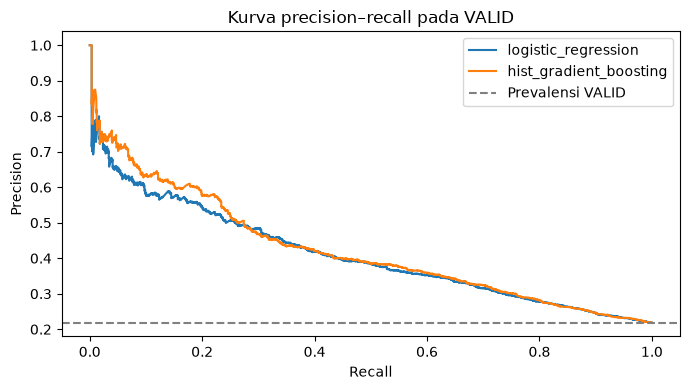

In [7]:
pembanding = Pipeline([
    ("preprocess", buat_preprocessing()),
    ("model", HistGradientBoostingClassifier(
        max_iter=150, max_leaf_nodes=15, l2_regularization=5,
        learning_rate=0.07, random_state=42))
])
pembanding.fit(X_train, y_train)
p_valid_pembanding = pembanding.predict_proba(X_valid)[:, 1]
model_kandidat = {"logistic_regression": baseline, "hist_gradient_boosting": pembanding}
prob_valid = {"logistic_regression": p_valid_baseline, "hist_gradient_boosting": p_valid_pembanding}
perbandingan = pd.DataFrame([
    {"model": nama, "AP_VALID": average_precision_score(y_valid, prob)}
    for nama, prob in prob_valid.items()
]).sort_values("AP_VALID", ascending=False)
display(perbandingan)
nama_terpilih = perbandingan.iloc[0]["model"]
model_terpilih = model_kandidat[nama_terpilih]
print("Terpilih berdasarkan VALID:", nama_terpilih)

plt.figure(figsize=(7, 4))
for nama, prob in prob_valid.items():
    precision, recall, _ = precision_recall_curve(y_valid, prob)
    plt.plot(recall, precision, label=nama)
plt.axhline(y_valid.mean(), color="gray", linestyle="--", label="Prevalensi VALID")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Kurva precision–recall pada VALID")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Threshold berbasis biaya pada VALID
False negative (paket terlambat tidak diperingatkan) diberi biaya simulasi Rp50.000; false positive (peringatan keliru) Rp5.000. Kita mencoba setiap skor VALID yang unik dan pilihan tanpa alarm, lalu mengambil biaya terkecil. Sorting membuat perhitungan tetap ringan.

Threshold model yang AP-nya tertinggi dipilih dari VALID model tersebut. Pemilihan AP dan threshold adalah dua langkah berbeda; biaya VALID yang minimum bukan jaminan manfaat pada dunia nyata.

In [8]:
BIAYA_FN, BIAYA_FP = 50000, 5000

def pilih_threshold(y, prob):
    y = np.asarray(y)
    prob = np.asarray(prob)
    urutan = np.argsort(-prob, kind="stable")
    skor, label = prob[urutan], y[urutan]
    tp = np.cumsum(label)
    fp = np.cumsum(1 - label)
    biaya = BIAYA_FN * (label.sum() - tp) + BIAYA_FP * fp
    akhir_skor_unik = np.r_[np.flatnonzero(skor[:-1] != skor[1:]), len(skor) - 1]
    posisi = akhir_skor_unik[np.argmin(biaya[akhir_skor_unik])]
    if BIAYA_FN * label.sum() < biaya[posisi]:
        return float(np.nextafter(skor[0], np.inf))
    return float(skor[posisi])

rekap_valid = []
for nama, prob in prob_valid.items():
    ambang = pilih_threshold(y_valid, prob)
    tn, fp, fn, tp = confusion_matrix(y_valid, prob >= ambang, labels=[0, 1]).ravel()
    rekap_valid.append({"model": nama, "threshold": ambang,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "precision": tp / (tp + fp) if tp + fp else 0,
        "recall": tp / (tp + fn) if tp + fn else 0,
        "persen_alarm": 100 * (tp + fp) / len(y_valid),
        "biaya_Rp": int(BIAYA_FN * fn + BIAYA_FP * fp)})
rekap_valid = pd.DataFrame(rekap_valid).set_index("model")
threshold = float(rekap_valid.loc[nama_terpilih, "threshold"])
display(rekap_valid)
biaya_selalu_alarm = int(BIAYA_FP * (y_valid == 0).sum())
biaya_tanpa_alarm = int(BIAYA_FN * (y_valid == 1).sum())
print("Biaya VALID selalu alarm:", biaya_selalu_alarm)
print("Biaya VALID tanpa alarm:", biaya_tanpa_alarm)
print("Selisih biaya VALID terhadap selalu alarm:",
      biaya_selalu_alarm - int(rekap_valid.loc[nama_terpilih, "biaya_Rp"]))


,threshold,TN,FP,FN,TP,precision,recall,persen_alarm,biaya_Rp
model,,,,,,,,,
logistic_regression,0.028309,0,5174,0,1449,0.218783,1.000000,100.000000,25870000
hist_gradient_boosting,0.066036,286,4888,27,1422,0.225357,0.981366,95.274045,25790000


Biaya VALID selalu alarm: 25870000
Biaya VALID tanpa alarm: 72450000
Selisih biaya VALID terhadap selalu alarm: 80000


## 10. Hasil TEST historis — bukan evaluasi ulang
Tabel ini ditranskripsikan dari `artifacts/TEST_EVALUATED_ONCE.json` eksperimen awal, bertanggal `2026-11-16T13:33:42.621928+07:00`. Sidik SHA-256 receipt: `b9a8b53baec16dc399f0ae50368b7cb4af55c2e5aa1c96d9e8894302e577e63c`. Salinan receipt asli disimpan terpisah bersama revisi lokal; tabel ini tidak memerlukan atau menyembunyikan payload paket.

| Model awal | AP VALID awal | AP TEST sekali pada eksperimen awal |
|---|---:|---:|
| Regresi logistik | 0.409362 | 0.360007 |
| HistGradientBoosting | 0.422425 | 0.367870 |

Model awal HGB memakai threshold `0.06603616610212668`; TEST berisi 6.744 paket. Receipt mencatat TN=281, FP=5.524, FN=9, TP=930; precision=0,1441 dan recall=0,9904. Sebanyak 6.454/6.744 paket (95,70%) mendapat alarm. Biaya simulasi Rp28.070.000 dibanding Rp29.025.000 jika semua diperingatkan, selisih Rp955.000 (3,29%). **Alarm hampir menyeluruh dan precision rendah membatasi kegunaannya.** Penghematan simulasi tidak membuktikan manfaat operasional.

Angka historis ini milik model beku awal, **bukan sertifikasi model hasil rerun di atas**, walaupun konfigurasinya sama. TEST tidak dinilai kembali di notebook ini. Model/metadata/receipt asli tidak ditimpa.

## 11. Contoh prediksi satu paket sintetis
Contoh ini bukan paket nyata dan bukan baris TEST. Input dibersihkan dengan aturan yang sama lalu diproses model hasil latihan di atas. Probabilitas adalah skor model, bukan kepastian. Rekomendasi hanya ilustrasi untuk demo; API proyek memiliki validasi input tersendiri dan menolak berat numerik ≤0 atau >100 kg (422), sedangkan nilai kosong dapat diimputasi.

In [9]:
contoh = pd.DataFrame([{
    "jam_pickup": 14, "jarak_km": 150, "jumlah_transit": 1, "janji_hari": 2,
    "berat_kg": 1.5, "kota_tujuan": "Jakarta", "layanan": "REG",
    "metode_bayar": "COD", "cuaca_saat_pickup": "cerah"
}], index=["DEMO_SINTETIS"])
prob_contoh = float(model_terpilih.predict_proba(bersihkan(contoh))[0, 1])
print("Contoh sintetis — probabilitas:", round(prob_contoh, 4))
print("Threshold VALID:", threshold)
print("Ilustrasi rekomendasi:", "tinjau/peringatkan CS" if prob_contoh >= threshold else "pemantauan biasa")


Contoh sintetis — probabilitas: 0.0934
Threshold VALID: 0.06603616610212668
Ilustrasi rekomendasi: tinjau/peringatkan CS


## 12. Menyimpan ringkasan VALID dan keterbatasan
Ekspor di bawah hanya menulis hasil VALID ke direktori kerja notebook saat ini. Tidak menyimpan model pengganti, tidak mengubah artefak aplikasi, dan tidak menulis skor TEST.

- AP VALID dipakai untuk perbandingan, bukan klaim akurasi atau keberhasilan bisnis.
- Threshold biaya rendah dapat membuat hampir semua paket mendapat alarm; beban kerja CS perlu dipertimbangkan.
- Dataset sintetis dan asumsi biaya tetap belum mewakili operasi nyata.
- Status rencana/realisasi transit serta mapping gambar topik perlu dikonfirmasi.
- Rerun dua model di sini hanya demonstrasi proses TRAIN/VALID. Model beku aplikasi dan hasil TEST awal tetap terpisah.
- Revisi notebook ini belum mendapat audit independen baru. Repo publik, aplikasi publik, video penjelasan anggota dan pengumpulan tugas masih proses terpisah; tidak ada submit dari notebook ini.

In [10]:
ringkasan = perbandingan.set_index("model").join(rekap_valid)
ringkasan.to_csv("ringkasan_validasi.csv")
print("Disimpan: ringkasan_validasi.csv (hanya TRAIN/VALID; tidak ada evaluasi TEST)")
display(ringkasan)


Disimpan: ringkasan_validasi.csv (hanya TRAIN/VALID; tidak ada evaluasi TEST)


,AP_VALID,threshold,TN,FP,FN,TP,precision,recall,persen_alarm,biaya_Rp
model,,,,,,,,,,
hist_gradient_boosting,0.422425,0.066036,286,4888,27,1422,0.225357,0.981366,95.274045,25790000
logistic_regression,0.409362,0.028309,0,5174,0,1449,0.218783,1.000000,100.000000,25870000
